In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    for file in files[:10]:
        print("  ", file)


Folder: /kaggle/input
Folder: /kaggle/input/datasets
Folder: /kaggle/input/datasets/hojjatk
Folder: /kaggle/input/datasets/hojjatk/mnist-dataset
   t10k-images.idx3-ubyte
   t10k-labels.idx1-ubyte
   train-images.idx3-ubyte
   train-labels.idx1-ubyte
Folder: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte
   t10k-images-idx3-ubyte
Folder: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte
   t10k-labels-idx1-ubyte
Folder: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte
   train-images-idx3-ubyte
Folder: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte
   train-labels-idx1-ubyte


In [2]:

import os
import pandas as pd

for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        path = os.path.join(root, file)
        if file.lower().endswith(".csv"):
            print("CSV found:", path)
            data = pd.read_csv(path, nrows=5)
            print(data.head())
            print("Columns:", len(data.columns))


Training images: (60000, 1, 28, 28)
Test images: (10000, 1, 28, 28)
Training device: cuda
Epoch 1/5, Loss: 0.2761
Epoch 2/5, Loss: 0.0770
Epoch 3/5, Loss: 0.0558
Epoch 4/5, Loss: 0.0462
Epoch 5/5, Loss: 0.0367

Test Accuracy: 99.06%

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.98      0.99       974
           9       0.98      1.00      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      

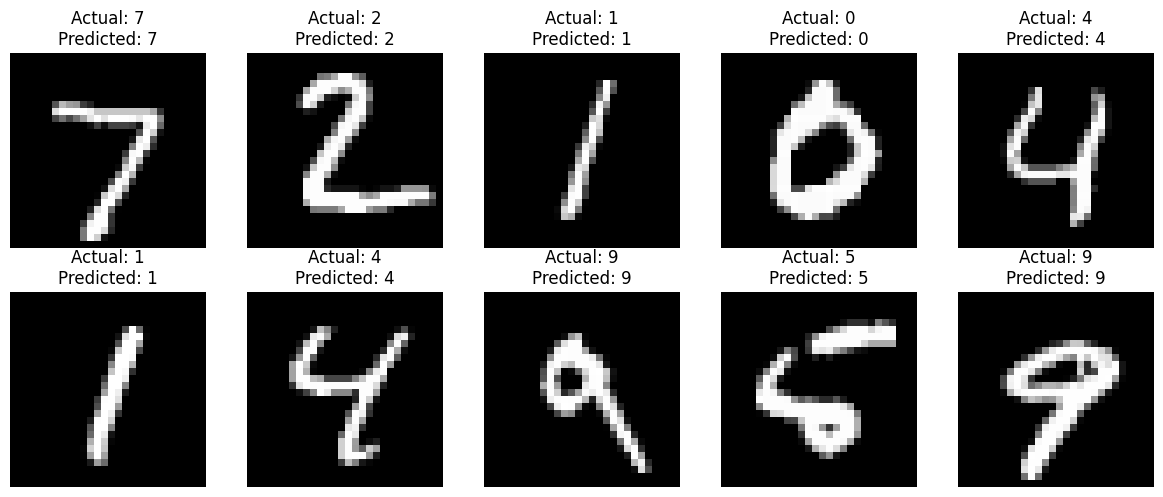

Saved model to /kaggle/working/mnist_cnn.pth


In [3]:

import os
import struct
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, classification_report

# 1. Dataset paths
base = "/kaggle/input/datasets/hojjatk/mnist-dataset"

def read_images(path):
    with open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8)
        return images.reshape(count, 1, rows, cols).copy()

def read_labels(path):
    with open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8).copy()

# Locate files automatically
paths = {}
for root, _, files in os.walk("/kaggle/input"):
    for file in files:
        if file in [
            "train-images.idx3-ubyte",
            "train-labels.idx1-ubyte",
            "t10k-images.idx3-ubyte",
            "t10k-labels.idx1-ubyte"
        ]:
            paths[file] = os.path.join(root, file)

required = [
    "train-images.idx3-ubyte",
    "train-labels.idx1-ubyte",
    "t10k-images.idx3-ubyte",
    "t10k-labels.idx1-ubyte"
]
assert all(name in paths for name in required), "MNIST files not found"

X_train = read_images(paths["train-images.idx3-ubyte"])
y_train = read_labels(paths["train-labels.idx1-ubyte"])
X_test = read_images(paths["t10k-images.idx3-ubyte"])
y_test = read_labels(paths["t10k-labels.idx1-ubyte"])

print("Training images:", X_train.shape)
print("Test images:", X_test.shape)

# 2. Normalize images and create data loaders
X_train = torch.tensor(X_train, dtype=torch.float32) / 255.0
X_test = torch.tensor(X_test, dtype=torch.float32) / 255.0
y_train = torch.tensor(y_train, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=128,
    shuffle=True
)
test_loader = DataLoader(
    TensorDataset(X_test, y_test),
    batch_size=256
)

# 3. Define one CNN model
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.25),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("Training device:", device)

# 4. Train the model
epochs = 5

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

# 5. Evaluate on test images
model.eval()
all_preds = []

with torch.no_grad():
    for images, _ in test_loader:
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test.numpy(), all_preds)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(y_test.numpy(), all_preds))

# 6. Display sample test images and predictions
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i, 0].numpy(), cmap="gray")
    ax.set_title(f"Actual: {y_test[i].item()}\nPredicted: {all_preds[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

# 7. Save the trained model
torch.save(model.state_dict(), "/kaggle/working/mnist_cnn.pth")
print("Saved model to /kaggle/working/mnist_cnn.pth")


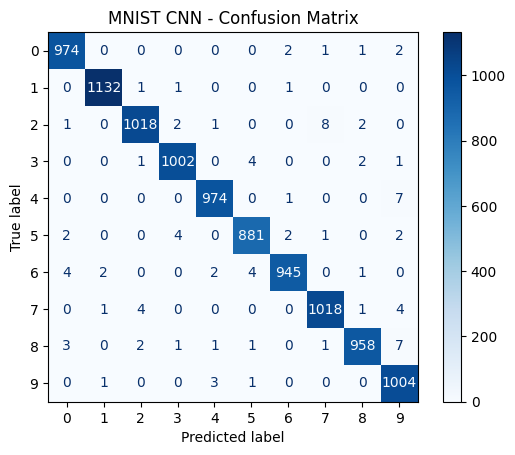

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Confusion matrix
model.eval()
all_preds = []

with torch.no_grad():
    for images, _ in test_loader:
        outputs = model(images.to(device))
        all_preds.extend(outputs.argmax(dim=1).cpu().numpy())

ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    all_preds,
    cmap="Blues"
)

plt.title("MNIST CNN - Confusion Matrix")
plt.show()

In [5]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test.numpy(), all_preds)

print("Project: MNIST Handwritten Digit Classification")
print("Model: Convolutional Neural Network (CNN)")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print(f"Test accuracy: {accuracy * 100:.2f}%")
print("Classes: Digits 0 to 9")

Project: MNIST Handwritten Digit Classification
Model: Convolutional Neural Network (CNN)
Training images: 60000
Testing images: 10000
Test accuracy: 99.06%
Classes: Digits 0 to 9


Training images: torch.Size([60000, 1, 28, 28])
Testing images: torch.Size([10000, 1, 28, 28])
Device: cuda
Epoch 1/5, Loss: 0.3419
Epoch 2/5, Loss: 0.1288
Epoch 3/5, Loss: 0.0850
Epoch 4/5, Loss: 0.0626
Epoch 5/5, Loss: 0.0473

ANN Test Accuracy: 97.83%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.98      0.98      0.98      1032
           3       0.97      0.99      0.98      1010
           4       0.99      0.97      0.98       982
           5       0.99      0.97      0.98       892
           6       0.97      0.98      0.98       958
           7       0.99      0.97      0.98      1028
           8       0.98      0.97      0.97       974
           9       0.96      0.98      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg     

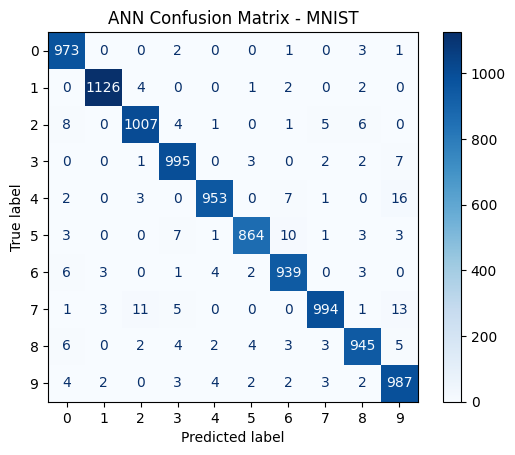

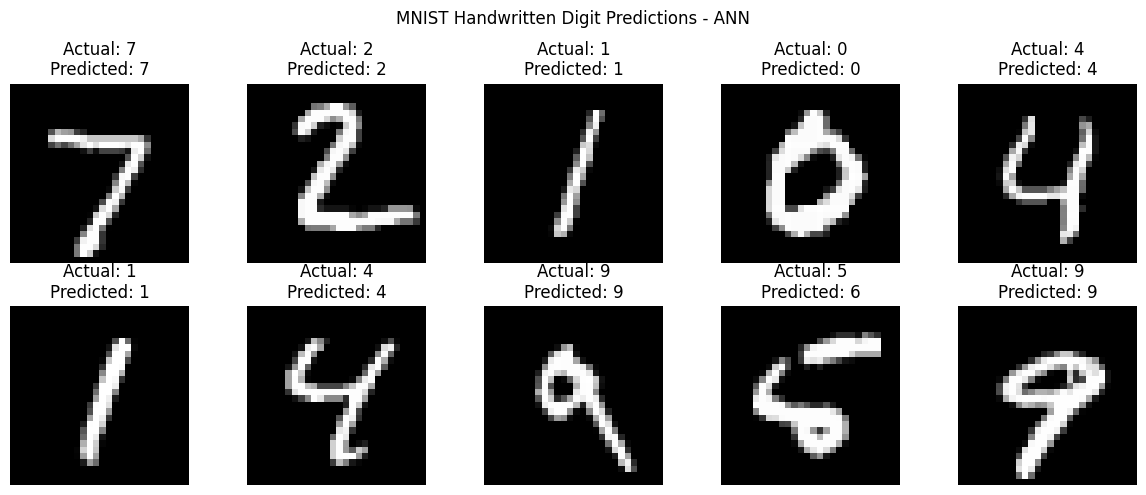

ANN model saved successfully!


In [6]:

import os
import struct
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# 1. Load MNIST dataset
def read_images(path):
    with open(path, "rb") as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        data = f.read()
    images = torch.frombuffer(bytearray(data), dtype=torch.uint8)
    return images.reshape(num, 1, rows, cols).float() / 255.0

def read_labels(path):
    with open(path, "rb") as f:
        magic, num = struct.unpack(">II", f.read(8))
        data = f.read()
    return torch.frombuffer(bytearray(data), dtype=torch.uint8).long()

# Find dataset files
files = {}
for root, dirs, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        if filename in [
            "train-images.idx3-ubyte",
            "train-labels.idx1-ubyte",
            "t10k-images.idx3-ubyte",
            "t10k-labels.idx1-ubyte"
        ]:
            files[filename] = os.path.join(root, filename)

X_train = read_images(files["train-images.idx3-ubyte"])
y_train = read_labels(files["train-labels.idx1-ubyte"])
X_test = read_images(files["t10k-images.idx3-ubyte"])
y_test = read_labels(files["t10k-labels.idx1-ubyte"])

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

# 2. Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# 3. Prepare data for ANN
train_data = TensorDataset(X_train.reshape(-1, 784), y_train)
test_data = TensorDataset(X_test.reshape(-1, 784), y_test)

train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True
)
test_loader = DataLoader(
    test_data, batch_size=256, shuffle=False
)

# 4. Build ANN model
ann_model = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

# 5. Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    ann_model.parameters(), lr=0.001
)

# 6. Train ANN
for epoch in range(5):
    ann_model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = ann_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/5, "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

# 7. Evaluate model
ann_model.eval()
predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        outputs = ann_model(images.to(device))
        predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

y_test_np = y_test.numpy()
accuracy = accuracy_score(y_test_np, predictions)

print(f"\nANN Test Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_np, predictions))

# 8. Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_np, predictions, cmap="Blues"
)
plt.title("ANN Confusion Matrix - MNIST")
plt.show()

# 9. Display 10 handwritten digit images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i, 0].numpy(), cmap="gray")
    ax.set_title(
        f"Actual: {y_test[i].item()}\n"
        f"Predicted: {predictions[i]}"
    )
    ax.axis("off")

plt.suptitle("MNIST Handwritten Digit Predictions - ANN")
plt.tight_layout()
plt.show()

# 10. Save trained model
torch.save(
    ann_model.state_dict(),
    "/kaggle/working/mnist_ann.pth"
)
print("ANN model saved successfully!")
